# ICC Cricket World Cup 2023 - Corrected Analysis
Re-built from the four raw CSV files (`batting_summary`, `bowling_summary`, `match_schedule_results`, `world_cup_players_info`).
It fixes the problems found in the earlier notebook: wrong innings order, duplicated rows for matches 10 and 47, a wrong winner for match 33, and extras missing from team totals.
**Not possible with this data:** Player of the Match analysis (no MoM column exists).

## 1. Imports and load data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_DIR = next(d for d in [".", "/content", "/mnt/user-data/uploads"]
                if os.path.exists(os.path.join(d, "batting_summary.csv")))

batting = pd.read_csv(f"{DATA_DIR}/batting_summary.csv", encoding="utf-8-sig")
bowling = pd.read_csv(f"{DATA_DIR}/bowling_summary.csv", encoding="utf-8-sig")
matches = pd.read_csv(f"{DATA_DIR}/match_schedule_results.csv", encoding="utf-8-sig")
players = pd.read_csv(f"{DATA_DIR}/world_cup_players_info.csv", encoding="utf-8-sig")

for name, df in [("batting", batting), ("bowling", bowling), ("matches", matches), ("players", players)]:
    print(f"{name:8s} shape={df.shape}  duplicate rows={df.duplicated().sum()}")
print("\nMissing values:")
print("batting:", batting.isnull().sum()[batting.isnull().sum() > 0].to_dict())
print("players:", players.isnull().sum()[players.isnull().sum() > 0].to_dict())

batting  shape=(916, 11)  duplicate rows=0
bowling  shape=(574, 9)  duplicate rows=0
matches  shape=(48, 7)  duplicate rows=0
players  shape=(151, 7)  duplicate rows=0

Missing values:
batting: {'Dismissal': 2}
players: {'image_of_player': 66, 'bowlingStyle': 6, 'description': 17}


## 2. Standardise columns and data types

In [2]:
def clean_cols(df):
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    return df

batting, bowling, matches, players = map(clean_cols, [batting, bowling, matches, players])

batting = batting.rename(columns={"team_innings": "team", "batsman_name": "batsman", "4s": "fours", "6s": "sixes"})
bowling = bowling.rename(columns={"bowling_team": "team", "bowler_name": "bowler"})
matches = matches.rename(columns={"team1": "team_1", "team2": "team_2"}).drop(columns=["scorecard_url"])

for df, cols in [(batting, ["runs", "balls", "fours", "sixes", "strike_rate"]),
                 (bowling, ["overs", "maidens", "runs", "wickets", "economy"])]:
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

for df in (batting, bowling, matches):
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]) or pd.api.types.is_object_dtype(df[c]):
            df[c] = df[c].str.strip()

batting["dismissal"] = batting["dismissal"].fillna("not out")
batting["is_out"] = ~batting["dismissal"].str.contains("not out", case=False)
matches["date"] = pd.to_datetime(matches["date"] + " 2023", format="%B %d %Y", errors="coerce")

print(batting.dtypes.to_string())
print("\nunparsed dates:", matches["date"].isna().sum())

match_no              int64
match_between           str
team                    str
batsman                 str
batting_position      int64
dismissal               str
runs                  int64
balls                 int64
fours                 int64
sixes                 int64
strike_rate         float64
is_out                 bool

unparsed dates: 0


## 3. Data fix 1 - duplicated rows for matches 10 and 47
Matches 10 and 47 (South Africa vs Australia, league match and semi-final) are both loaded under *both* match numbers in `batting_summary.csv`. Rows 160-199 belong to match 10 and rows 200-239 to match 47.

In [3]:
dup_mask = batting.duplicated(["match_no", "batsman"], keep=False)
print("Rows with the same batsman twice in one match:", int(dup_mask.sum()),
      "-> matches", [int(x) for x in sorted(batting.loc[dup_mask, "match_no"].unique())])

idx = batting.index.to_series()
bad = ((batting.match_no == 47) & idx.between(160, 199)) | ((batting.match_no == 10) & idx.between(200, 239))
rows_dropped = int(bad.sum())
batting = batting.loc[~bad].reset_index(drop=True)

assert not batting.duplicated(["match_no", "batsman"]).any()
print("Rows dropped:", rows_dropped, "| batting rows now:", len(batting))
for k in (10, 47):
    print(f"Match {k} batsman-run totals:", batting[batting.match_no == k].groupby("team").runs.sum().to_dict())

Rows with the same batsman twice in one match: 68 -> matches [10, 47]
Rows dropped: 40 | batting rows now: 876
Match 10 batsman-run totals: {'Australia': 160, 'South Africa': 298}
Match 47 batsman-run totals: {'Australia': 198, 'South Africa': 201}


## 4. Data fix 2 - innings order
The old notebook assumed `team_1` bats first, which is false. The batting file lists each match's innings in order, so the first team to appear is the team that batted first.

In [4]:
order = batting.groupby("match_no", sort=False)["team"].agg(lambda s: list(dict.fromkeys(s)))
assert (order.map(len) == 2).all() and len(order) == 48

batting["innings"] = [order[m].index(t) + 1 for m, t in zip(batting.match_no, batting.team)]
matches["bat_first"] = matches.match_no.map(lambda k: order[k][0])
matches["bat_second"] = matches.match_no.map(lambda k: order[k][1])

print("Share of matches where team_1 batted first:", round((matches.team_1 == matches.bat_first).mean() * 100, 1), "%  (the old code assumed 100%)")
print(matches.loc[matches.match_no.isin([4, 5]), ["match_no", "team_1", "team_2", "bat_first", "bat_second"]].to_string(index=False))

# Team totals: the batting file has no extras, so estimate the total from runs conceded by the opposition's bowlers
# (includes wides/no-balls, excludes byes and leg-byes - within a few runs of the true total).
bowl_conceded = bowling.groupby(["match_no", "team"]).runs.sum().to_dict()
inn = (batting.groupby(["match_no", "innings", "team"])
       .agg(batsman_runs=("runs", "sum"), wickets_lost=("is_out", "sum")).reset_index())
inn["opp"] = [order[m][1] if t == order[m][0] else order[m][0] for m, t in zip(inn.match_no, inn.team)]
inn["est_total"] = [bowl_conceded[(m, o)] for m, o in zip(inn.match_no, inn.opp)]
print("\nExample - match 4:", inn[inn.match_no == 4][["team", "batsman_runs", "est_total"]].to_dict("records"), "(real: South Africa 428, Sri Lanka 326)")

a = inn[inn.innings == 1].set_index("match_no"); b2 = inn[inn.innings == 2].set_index("match_no")
matches["first_total"] = matches.match_no.map(a.est_total)
matches["second_total"] = matches.match_no.map(b2.est_total)
matches["second_wickets"] = matches.match_no.map(b2.wickets_lost)

Share of matches where team_1 batted first: 52.1 %  (the old code assumed 100%)
 match_no       team_1    team_2    bat_first bat_second
        4 South Africa Sri Lanka South Africa  Sri Lanka
        5        India Australia    Australia      India

Example - match 4: [{'team': 'South Africa', 'batsman_runs': 405, 'est_total': 427}, {'team': 'Sri Lanka', 'batsman_runs': 306, 'est_total': 321}] (real: South Africa 428, Sri Lanka 326)


## 5. Data fix 3 - validate winners
A winner is suspicious if the chasing side was all out for *fewer* runs than the target and is still listed as the winner.

In [5]:
flag = matches[(matches.winner == matches.bat_second) & (matches.second_wickets >= 10) & (matches.second_total < matches.first_total)]
print("Suspicious winners:")
print(flag[["match_no", "team_1", "team_2", "winner", "first_total", "second_total", "second_wickets"]].to_string(index=False))
assert list(flag.match_no) == [33]

WINNER_FIX = {33: "India"}          # India 357/8, Sri Lanka all out for 55
matches["winner_raw"] = matches["winner"]
matches["winner"] = [WINNER_FIX.get(m, w) for m, w in zip(matches.match_no, matches.winner)]

# Rain-affected chases: chaser not all out, finished far below the first-innings score (DLS result)
dls = matches[(matches.winner == matches.bat_second) & (matches.second_wickets < 10) & (matches.second_total + 40 < matches.first_total)]
print("\nDLS-style results:", dls[["match_no", "team_1", "team_2", "winner"]].to_dict("records"))

matches["result_type"] = np.where(matches.winner == matches.bat_first, "runs", "wickets")
matches.loc[matches.match_no.isin(dls.match_no), "result_type"] = "runs (DLS)"
matches["won_batting_first"] = matches.winner == matches.bat_first
print("\nresult types:", matches.result_type.value_counts().to_dict())

Suspicious winners:
 match_no team_1    team_2    winner  first_total  second_total  second_wickets
       33  India Sri Lanka Sri Lanka          346            49              10

DLS-style results: [{'match_no': 35, 'team_1': 'New Zealand', 'team_2': 'Pakistan', 'winner': 'Pakistan'}]

result types: {'wickets': 24, 'runs': 23, 'runs (DLS)': 1}


## 6. Team results

In [6]:
played = pd.concat([matches.team_1, matches.team_2]).value_counts()
team = pd.DataFrame({"matches": played})
team["wins"] = matches.winner.value_counts()
team = team.fillna(0).astype(int)
team["win_pct"] = (team.wins / team.matches * 100).round(1)
team["bat_first_played"] = matches.bat_first.value_counts().reindex(team.index).fillna(0).astype(int)
team["bat_first_wins"] = matches[matches.won_batting_first].winner.value_counts().reindex(team.index).fillna(0).astype(int)
team["chase_played"] = matches.bat_second.value_counts().reindex(team.index).fillna(0).astype(int)
team["chase_wins"] = team.wins - team.bat_first_wins
team = team.sort_values(["wins", "win_pct"], ascending=False)
print(team.to_string())

won_by = matches.groupby(["winner", "result_type"]).size().unstack(fill_value=0)
print("\nWon by runs / wickets:")
print(won_by.to_string())

n_bf = int(matches.won_batting_first.sum())
print(f"\nBatting first won {n_bf}/48 = {n_bf/48*100:.1f}% | chasing won {48-n_bf}/48 = {(48-n_bf)/48*100:.1f}%")

              matches  wins  win_pct  bat_first_played  bat_first_wins  chase_played  chase_wins
India              11    10     90.9                 6               5             5           5
Australia          11     9     81.8                 5               4             6           5
South Africa       10     7     70.0                 6               5             4           2
New Zealand        10     5     50.0                 4               2             6           3
Pakistan            9     4     44.4                 4               1             5           3
Afghanistan         9     4     44.4                 5               1             4           3
England             9     3     33.3                 5               3             4           0
Bangladesh          9     2     22.2                 4               0             5           2
Netherlands         9     2     22.2                 4               2             5           0
Sri Lanka           9     2   

## 7. Venue analysis

In [7]:
matches["venue_clean"] = (matches.venue
    .str.replace("Himachal Pradesh Cricket Association Stadium, Dharamsala", "Dharamsala")
    .str.replace("Ekana Cricket Stadium Lucknow", "Lucknow"))
venue_stadium = {"Mumbai": "Wankhede Stadium", "Lucknow": "Ekana Stadium", "Ahmedabad": "Narendra Modi Stadium",
                 "Kolkata": "Eden Gardens", "Delhi": "Arun Jaitley Stadium", "Chennai": "MA Chidambaram Stadium",
                 "Bengaluru": "M. Chinnaswamy Stadium", "Pune": "MCA Stadium", "Hyderabad": "Rajiv Gandhi Stadium",
                 "Dharamsala": "HPCA Stadium"}

venue = (matches.groupby("venue_clean")
         .agg(matches=("match_no", "count"), bat_first_wins=("won_batting_first", "sum"),
              avg_first_innings=("first_total", "mean")).reset_index())
venue["chase_wins"] = venue.matches - venue.bat_first_wins
venue["bat_first_win_pct"] = (venue.bat_first_wins / venue.matches * 100).round(1)
venue["avg_first_innings"] = venue.avg_first_innings.round(0)
venue["stadium"] = venue.venue_clean.map(venue_stadium)
venue = venue.sort_values("bat_first_win_pct", ascending=False).reset_index(drop=True)
print(venue[["venue_clean", "stadium", "matches", "bat_first_wins", "chase_wins", "bat_first_win_pct", "avg_first_innings"]].to_string(index=False))
print("\nBest venue to bat first :", venue.iloc[0].venue_clean, f"({venue.iloc[0].bat_first_win_pct}%)")
low = venue[venue.bat_first_win_pct == venue.bat_first_win_pct.min()].venue_clean.tolist()
print("Best venues to chase    :", low, f"(batting first won only {venue.bat_first_win_pct.min()}%)")
print("Note: only 3-5 matches per venue, so treat these as indicative, not conclusive.")

venue_clean                stadium  matches  bat_first_wins  chase_wins  bat_first_win_pct  avg_first_innings
     Mumbai       Wankhede Stadium        5               4           1               80.0              360.0
  Hyderabad   Rajiv Gandhi Stadium        3               2           1               66.7              315.0
    Kolkata           Eden Gardens        5               3           2               60.0              257.0
      Delhi   Arun Jaitley Stadium        5               3           2               60.0              330.0
 Dharamsala           HPCA Stadium        5               3           2               60.0              281.0
  Bengaluru M. Chinnaswamy Stadium        5               2           3               40.0              296.0
       Pune            MCA Stadium        5               2           3               40.0              296.0
    Lucknow          Ekana Stadium        5               2           3               40.0              234.0
  Ahmedaba

## 8. Top performer in each match

In [8]:
top_scorer = (batting.sort_values(["match_no", "runs", "balls"], ascending=[True, False, True])
              .groupby("match_no").head(1)[["match_no", "match_between", "batsman", "team", "runs", "balls"]])
best_bowler = (bowling.sort_values(["match_no", "wickets", "runs", "overs"], ascending=[True, False, True, False])
               .groupby("match_no").head(1)[["match_no", "match_between", "bowler", "team", "wickets", "runs", "overs"]])

print("Best scorer in a match (times):")
print(top_scorer.batsman.value_counts().head(8).to_string())
print("\nBest bowler in a match (most wickets, then fewest runs) (times):")
print(best_bowler.bowler.value_counts().head(8).to_string())

mx = bowling[bowling.wickets == bowling.groupby("match_no").wickets.transform("max")]
print("\nMost wickets in a match, ties counted for everyone (times):")
print(mx.bowler.value_counts().head(6).to_string())

Best scorer in a match (times):
batsman
Rohit Sharma             3
Daryl Mitchell           3
Rassie van der Dussen    2
Quinton de Kock          2
Kusal Janith Perera      2
Scott Edwards            2
Virat Kohli              2
Glenn Maxwell            2

Best bowler in a match (most wickets, then fewest runs) (times):
bowler
Gerald Coetzee        4
Mohammed Shami        4
Ravindra Jadeja       3
Adam Zampa            3
Jasprit Bumrah        2
Lockie Ferguson       2
Shaheen Afridi        2
Dilshan Madushanka    2

Most wickets in a match, ties counted for everyone (times):
bowler
Ravindra Jadeja    5
Gerald Coetzee     4
Jasprit Bumrah     4
Adam Zampa         4
Mohammed Shami     4
Bas de Leede       3


## 9. Tournament leaders

In [9]:
def overs_to_balls(o):
    full = int(o); return full * 6 + int(round((o - full) * 10))

bat = (batting.groupby("batsman")
       .agg(team=("team", "first"), innings=("runs", "count"), runs=("runs", "sum"), balls=("balls", "sum"),
            outs=("is_out", "sum"), highest=("runs", "max"),
            hundreds=("runs", lambda s: int((s >= 100).sum())),
            fifties=("runs", lambda s: int(((s >= 50) & (s < 100)).sum())))
       .reset_index())
bat["average"] = (bat.runs / bat.outs.replace(0, np.nan)).round(2)
bat["strike_rate"] = (bat.runs / bat.balls * 100).round(1)
top_bat = bat.sort_values("runs", ascending=False).head(10).reset_index(drop=True)
print("Top 10 run scorers:"); print(top_bat[["batsman", "team", "innings", "runs", "average", "strike_rate", "hundreds", "fifties"]].to_string())

bowling["balls"] = bowling.overs.apply(overs_to_balls)
bwl = (bowling.groupby("bowler")
       .agg(team=("team", "first"), matches=("match_no", "nunique"), wickets=("wickets", "sum"),
            runs=("runs", "sum"), balls=("balls", "sum")).reset_index())
bwl["average"] = (bwl.runs / bwl.wickets.replace(0, np.nan)).round(2)
bwl["economy"] = (bwl.runs / (bwl.balls / 6)).round(2)
bwl["strike_rate"] = (bwl.balls / bwl.wickets.replace(0, np.nan)).round(1)
top_bowl = bwl.sort_values(["wickets", "average"], ascending=[False, True]).head(10).reset_index(drop=True)
print("\nTop 10 wicket takers:"); print(top_bowl[["bowler", "team", "matches", "wickets", "average", "economy", "strike_rate"]].to_string())
print("\nCheck - Quinton de Kock:", int(bat[bat.batsman == "Quinton de Kock"].runs.iloc[0]), "runs,", int(bat[bat.batsman == "Quinton de Kock"].hundreds.iloc[0]), "hundreds (old notebook: 706 / 5)")

Top 10 run scorers:
                 batsman          team  innings  runs  average  strike_rate  hundreds  fifties
0            Virat Kohli         India       11   765    95.62         90.3         3        6
1           Rohit Sharma         India       11   597    54.27        125.9         1        3
2        Quinton de Kock  South Africa       10   594    59.40        107.0         4        0
3        Rachin Ravindra   New Zealand       10   578    64.22        106.4         3        2
4         Daryl Mitchell   New Zealand        9   552    69.00        111.1         2        2
5           David Warner     Australia       11   535    48.64        108.3         2        2
6           Shreyas Iyer         India       11   530    66.25        113.2         2        3
7               KL Rahul         India       10   452    75.33         90.8         1        2
8  Rassie van der Dussen  South Africa       10   448    49.78         84.5         2        2
9         Mitchell Marsh     A

## 10. Pressure situations (estimated totals)

In [10]:
big = matches[matches.first_total >= 300]
chase300 = (big.groupby("bat_second").agg(chases=("match_no", "count"), successful=("winner", lambda s: 0)).reset_index())
chase300["successful"] = [int(((big.bat_second == t) & (big.winner == t)).sum()) for t in chase300.bat_second]
chase300["success_pct"] = (chase300.successful / chase300.chases * 100).round(1)
print(f"Chasing a 300+ first-innings total: {len(big)} matches, chasers won {int((big.winner == big.bat_second).sum())}")
print(chase300.sort_values("success_pct", ascending=False).to_string(index=False))

small = matches[matches.first_total < 200]
print(f"\nDefending under 200: {len(small)} matches, defenders won {int((small.winner == small.bat_first).sum())}")
print(small[["match_no", "bat_first", "first_total", "bat_second", "second_total", "winner"]].to_string(index=False))

bins = pd.cut(matches.first_total, [0, 199, 249, 299, 349, 999], labels=["<200", "200-249", "250-299", "300-349", "350+"])
rng = matches.groupby(bins, observed=True).agg(matches=("match_no", "count"), defender_wins=("won_batting_first", "sum"))
rng["defend_win_pct"] = (rng.defender_wins / rng.matches * 100).round(1)
print("\nBy first-innings total:"); print(rng.to_string())

hi = inn[inn.est_total >= 300].groupby("team").size().sort_values(ascending=False)
print("\n300+ totals by team:", hi.to_dict())

Chasing a 300+ first-innings total: 18 matches, chasers won 2
  bat_second  chases  successful  success_pct
    Pakistan       4           2         50.0
   Australia       1           0          0.0
     England       1           0          0.0
  Bangladesh       2           0          0.0
 Netherlands       4           0          0.0
 New Zealand       3           0          0.0
South Africa       1           0          0.0
   Sri Lanka       2           0          0.0

Defending under 200: 6 matches, defenders won 0
 match_no   bat_first  first_total  bat_second  second_total      winner
        3 Afghanistan          156  Bangladesh           155  Bangladesh
        5   Australia          193       India           199       India
       12    Pakistan          188       India           191       India
       25     England          153   Sri Lanka           160   Sri Lanka
       34 Netherlands          177 Afghanistan           178 Afghanistan
       41   Sri Lanka          170 Ne

## 11. Charts

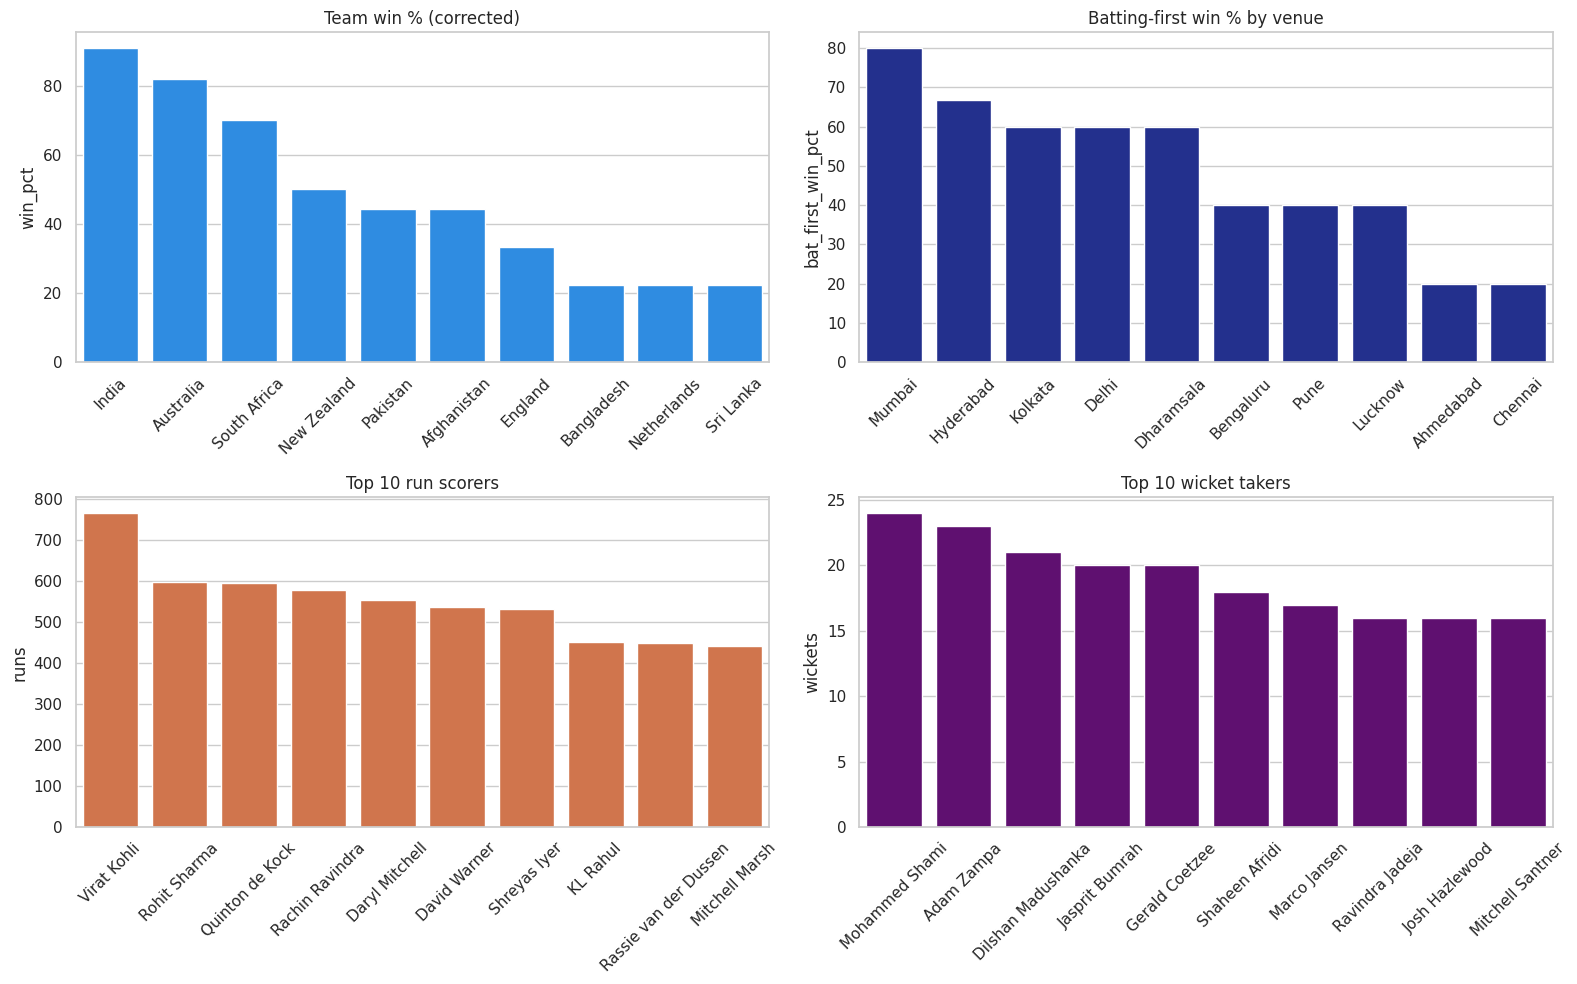

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(16, 10))
t = team.reset_index().rename(columns={"index": "team"})
sns.barplot(data=t, x="team", y="win_pct", ax=ax[0, 0], color="#118DFF"); ax[0, 0].set_title("Team win % (corrected)")
sns.barplot(data=venue, x="venue_clean", y="bat_first_win_pct", ax=ax[0, 1], color="#12239E"); ax[0, 1].set_title("Batting-first win % by venue")
sns.barplot(data=top_bat, x="batsman", y="runs", ax=ax[1, 0], color="#E66C37"); ax[1, 0].set_title("Top 10 run scorers")
sns.barplot(data=top_bowl, x="bowler", y="wickets", ax=ax[1, 1], color="#6A0080"); ax[1, 1].set_title("Top 10 wicket takers")
for a_ in ax.ravel():
    a_.tick_params(axis="x", rotation=45); a_.set_xlabel("")
plt.tight_layout(); plt.show()